In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("Marks_Combined_v6.csv",low_memory=False)

print(df.shape)
df.describe()
df.info()
print(df.head())

(385, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 385 entries, 0 to 384
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Coursework        381 non-null    float64
 1   Oral              381 non-null    float64
 2   Total_Attendance  385 non-null    float64
 3   score_exam        385 non-null    float64
 4   doctor_id         385 non-null    object 
 5   course_code       385 non-null    object 
dtypes: float64(4), object(2)
memory usage: 18.2+ KB
   Coursework  Oral  Total_Attendance  score_exam doctor_id course_code
0        32.0   7.0               7.0       15.33     DR001     COMP202
1        33.0   8.0               5.5       15.50     DR001     COMP202
2        35.0   8.0               3.0       15.33     DR001     COMP202
3        22.0   5.0               2.0        9.67     DR001     COMP202
4        33.0   8.0               5.5       15.50     DR001     COMP202


In [2]:
print(df.isnull().sum())

Coursework          4
Oral                4
Total_Attendance    0
score_exam          0
doctor_id           0
course_code         0
dtype: int64


In [3]:
print(df.duplicated().sum())

179


In [4]:
cat_col = [col for col in df.columns if df[col].dtype == 'object']

num_col = [col for col in df.columns if df[col].dtype != 'object']

print(cat_col)
print(num_col)

['doctor_id', 'course_code']
['Coursework', 'Oral', 'Total_Attendance', 'score_exam']


In [5]:
print("Doctors:")
print(df['doctor_id'].value_counts())

print("\nCourses:")
print(df['course_code'].value_counts())

Doctors:
doctor_id
DR002    199
DR001    186
Name: count, dtype: int64

Courses:
course_code
COMP302    199
COMP202    186
Name: count, dtype: int64


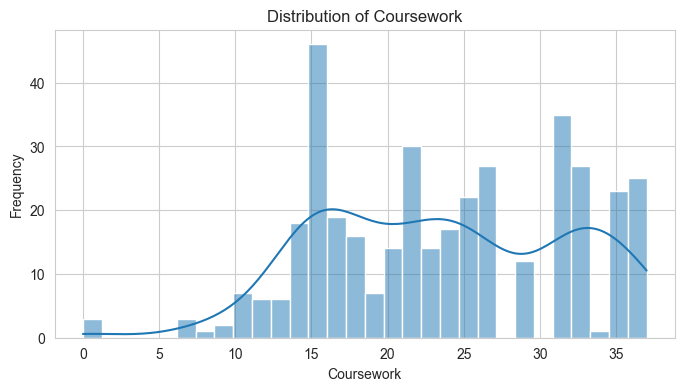

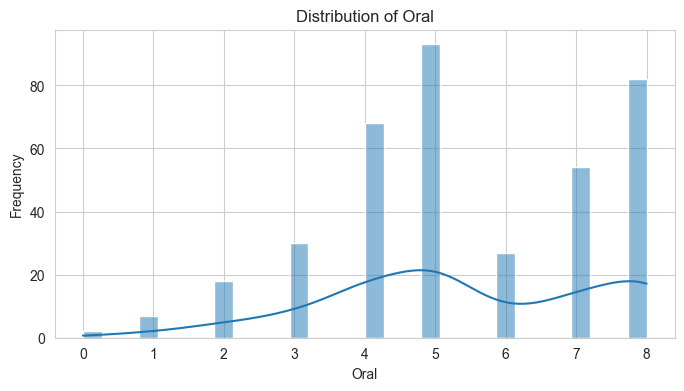

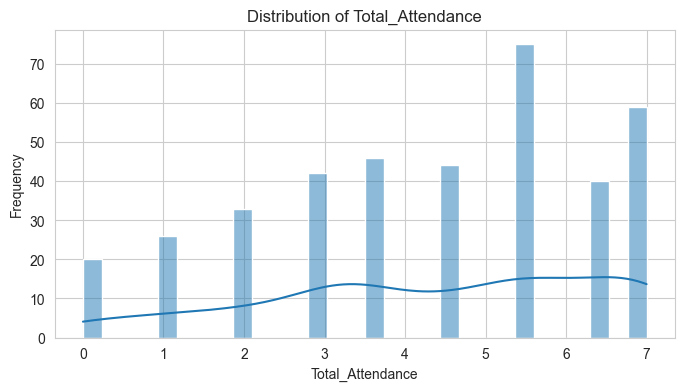

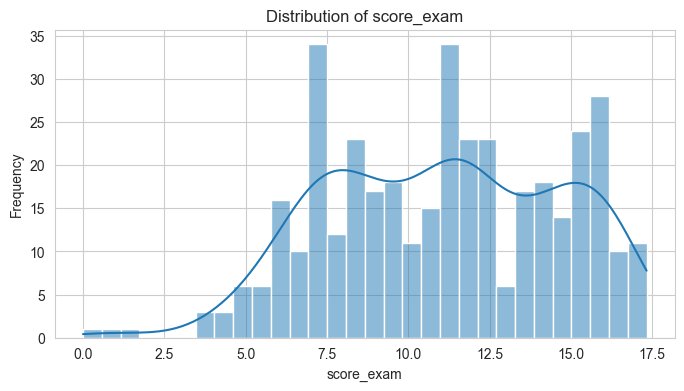

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')

numerical_cols = [
    'Coursework',
    'Oral',
    'Total_Attendance',
    'score_exam'
]

for col in numerical_cols:

    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=df,
        x=col,
        kde=True,
        bins=30
    )

    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

    plt.show()

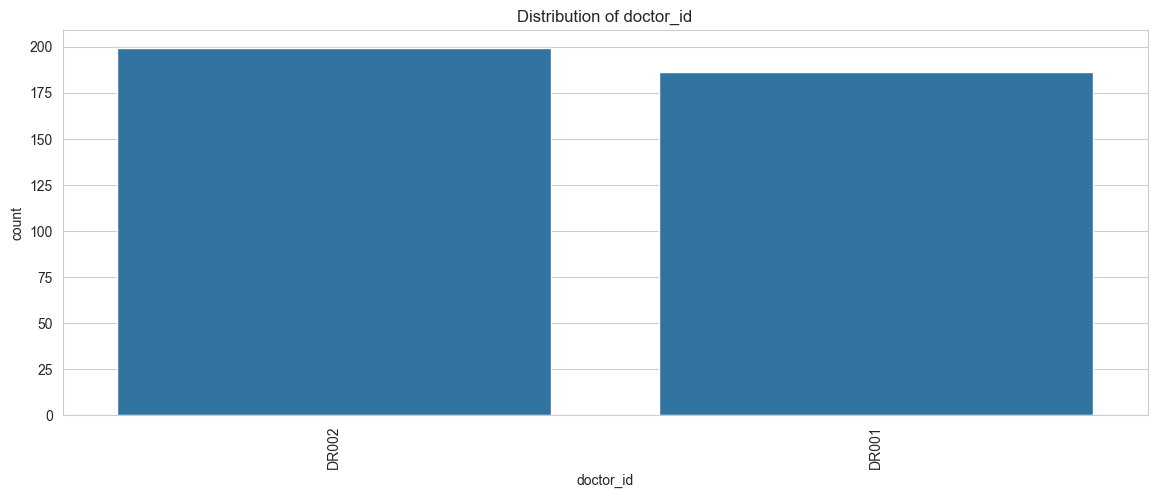

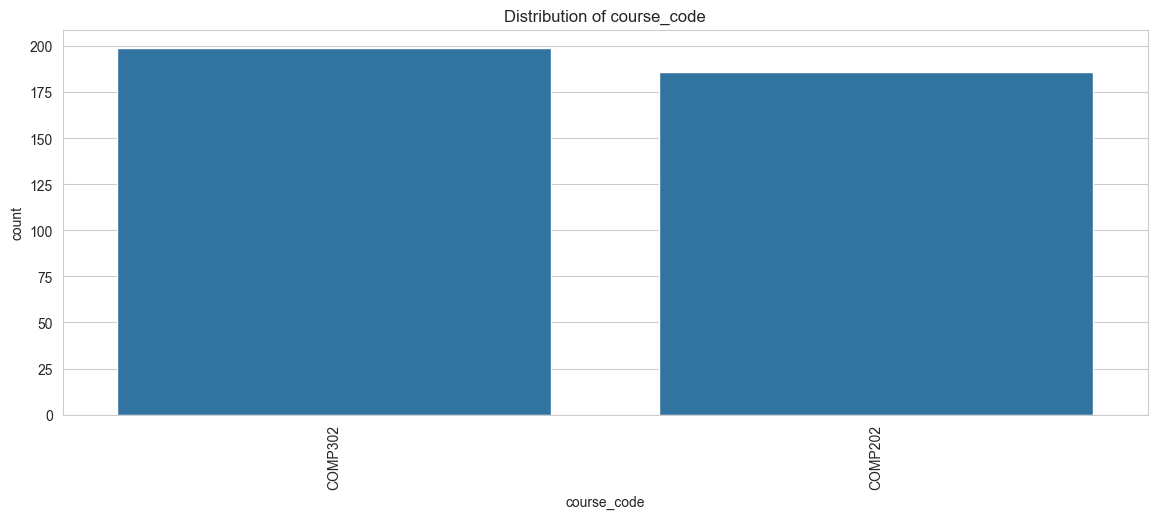

In [7]:
categorical_cols = ['doctor_id', 'course_code']

for col in categorical_cols:
    plt.figure(figsize=(14, 5))

    sns.countplot(
        data=df,
        x=col,
        order=df[col].value_counts().index
    )

    plt.title(f'Distribution of {col}')
    plt.xticks(rotation=90)
    plt.show()

In [8]:
# Check missing values
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})

print(missing)

                  Missing Count  Missing Percentage
Coursework                    4            1.038961
Oral                          4            1.038961
Total_Attendance              0            0.000000
score_exam                    0            0.000000
doctor_id                     0            0.000000
course_code                   0            0.000000


In [9]:
# Display rows containing missing values
missing_rows = df[df.isnull().any(axis=1)]

print(missing_rows)

     Coursework  Oral  Total_Attendance  score_exam doctor_id course_code
137         NaN   NaN               3.5         3.5     DR001     COMP202
140         NaN   NaN               5.5         5.5     DR001     COMP202
178         NaN   NaN               5.5         5.5     DR001     COMP202
181         NaN   NaN               4.5         4.5     DR001     COMP202


In [10]:
# Check unique values
for col in df.columns:
    print(df[col].value_counts(dropna=False))

Coursework
33.0    27
15.0    27
32.0    25
35.0    23
25.0    22
37.0    22
17.0    19
22.0    19
16.0    19
14.0    18
24.0    17
18.0    16
27.0    16
20.0    14
23.0    14
29.0    12
26.0    11
21.0    11
31.0    10
19.0     7
12.0     6
13.0     6
NaN      4
10.0     4
11.0     3
36.0     3
7.0      3
9.0      2
0.0      2
34.0     1
1.0      1
8.0      1
Name: count, dtype: int64
Oral
5.0    93
8.0    82
4.0    68
7.0    54
3.0    30
6.0    27
2.0    18
1.0     7
NaN     4
0.0     2
Name: count, dtype: int64
Total_Attendance
5.5    75
7.0    59
3.5    46
4.5    44
3.0    42
6.5    40
2.0    33
1.0    26
0.0    20
Name: count, dtype: int64
score_exam
8.17     14
11.33    13
9.50     13
12.33    12
7.50     12
         ..
0.00      1
1.00      1
8.67      1
5.83      1
6.50      1
Name: count, Length: 79, dtype: int64
doctor_id
DR002    199
DR001    186
Name: count, dtype: int64
course_code
COMP302    199
COMP202    186
Name: count, dtype: int64


In [11]:
# Keep the original dataset unchanged
df_raw = df.copy()

# Calculate the threshold using the original final exam scores
threshold = df_raw["score_exam"].median()

# Create a working copy
df = df_raw.copy()

# Create the target before removing score_exam
df["Risk"] = df_raw["score_exam"].apply(
    lambda score: "High Risk" if score < threshold else "Low Risk"
)

# Remove score_exam to prevent data leakage
df.drop(columns=["score_exam"], inplace=True)

# Check the result
print(df.head())
print("Shape:", df.shape)
print(df.info())

print("Threshold:", threshold)
print("\nRisk Distribution:")
print(df["Risk"].value_counts())
print("\nRisk Percentage:")
print(df["Risk"].value_counts(normalize=True) * 100)


   Coursework  Oral  Total_Attendance doctor_id course_code       Risk
0        32.0   7.0               7.0     DR001     COMP202   Low Risk
1        33.0   8.0               5.5     DR001     COMP202   Low Risk
2        35.0   8.0               3.0     DR001     COMP202   Low Risk
3        22.0   5.0               2.0     DR001     COMP202  High Risk
4        33.0   8.0               5.5     DR001     COMP202   Low Risk
Shape: (385, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 385 entries, 0 to 384
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Coursework        381 non-null    float64
 1   Oral              381 non-null    float64
 2   Total_Attendance  385 non-null    float64
 3   doctor_id         385 non-null    object 
 4   course_code       385 non-null    object 
 5   Risk              385 non-null    object 
dtypes: float64(3), object(3)
memory usage: 18.2+ KB
None
Threshold: 11.17

Ri

In [12]:
print(df_raw["score_exam"].describe())

count    385.000000
mean      11.064390
std        3.562884
min        0.000000
25%        8.170000
50%       11.170000
75%       14.170000
max       17.330000
Name: score_exam, dtype: float64


In [13]:
# Define features and target
X = df.drop(columns=["Risk"])
y = df["Risk"]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

print("\nFeatures shape:", X.shape)
print("Target shape:", y.shape)

print("\nMissing values:")
print(X.isnull().sum())

Features:
['Coursework', 'Oral', 'Total_Attendance', 'doctor_id', 'course_code']

Target:
Risk

Features shape: (385, 5)
Target shape: (385,)

Missing values:
Coursework          4
Oral                4
Total_Attendance    0
doctor_id           0
course_code         0
dtype: int64


In [14]:
# Split the raw dataset
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Keep the original feature columns unchanged.
# Imputation and encoding will be handled inside the Pipeline.
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("X_train columns:", X_train.columns.tolist())
print("X_test columns:", X_test.columns.tolist())


X_train shape: (308, 5)
X_test shape: (77, 5)
X_train columns: ['Coursework', 'Oral', 'Total_Attendance', 'doctor_id', 'course_code']
X_test columns: ['Coursework', 'Oral', 'Total_Attendance', 'doctor_id', 'course_code']


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

numerical_features = [
    "Coursework",
    "Oral",
    "Total_Attendance"
]

categorical_features = [
    "doctor_id",
    "course_code"
]

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing Pipeline Created Successfully")

Preprocessing Pipeline Created Successfully


In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create complete ML pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [17]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Make predictions
y_pred = model.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

# Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    y_pred,
    labels=["High Risk", "Low Risk"]
))

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.961038961038961

Confusion Matrix:
[[34  3]
 [ 0 40]]

Classification Report:
              precision    recall  f1-score   support

   High Risk       1.00      0.92      0.96        37
    Low Risk       0.93      1.00      0.96        40

    accuracy                           0.96        77
   macro avg       0.97      0.96      0.96        77
weighted avg       0.96      0.96      0.96        77



In [18]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

dt_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42
    ))
])

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

print(classification_report(y_test, dt_pred))

              precision    recall  f1-score   support

   High Risk       0.97      0.97      0.97        37
    Low Risk       0.97      0.97      0.97        40

    accuracy                           0.97        77
   macro avg       0.97      0.97      0.97        77
weighted avg       0.97      0.97      0.97        77



In [19]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

   High Risk       0.97      1.00      0.99        37
    Low Risk       1.00      0.97      0.99        40

    accuracy                           0.99        77
   macro avg       0.99      0.99      0.99        77
weighted avg       0.99      0.99      0.99        77



In [20]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

models = {
    "Logistic Regression": (model, y_pred),
    "Decision Tree": (dt_model, dt_pred),
    "Random Forest": (rf_model, rf_pred)
}

results = []

for name, (trained_model, predictions) in models.items():

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "High Risk Precision": precision_score(
            y_test, predictions,
            pos_label="High Risk"
        ),
        "High Risk Recall": recall_score(
            y_test, predictions,
            pos_label="High Risk"
        ),
        "High Risk F1": f1_score(
            y_test, predictions,
            pos_label="High Risk"
        )
    })

comparison_df = pd.DataFrame(results)

print(comparison_df.round(4))

                 Model  Accuracy  High Risk Precision  High Risk Recall  \
0  Logistic Regression     0.961               1.0000            0.9189   
1        Decision Tree     0.974               0.9730            0.9730   
2        Random Forest     0.987               0.9737            1.0000   

   High Risk F1  
0        0.9577  
1        0.9730  
2        0.9867  


In [21]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, f1_score, recall_score

# 5-fold cross validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Focus on High Risk
scoring = {
    "accuracy": "accuracy",
    "high_risk_recall": make_scorer(
        recall_score,
        pos_label="High Risk"
    ),
    "high_risk_f1": make_scorer(
        f1_score,
        pos_label="High Risk"
    )
}

models = {
    "Logistic Regression": model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model
}

cv_results = []

for name, clf in models.items():

    scores = cross_validate(
        clf,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    cv_results.append({
        "Model": name,
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Mean High Risk Recall": scores["test_high_risk_recall"].mean(),
        "Mean High Risk F1": scores["test_high_risk_f1"].mean(),
        "Std High Risk F1": scores["test_high_risk_f1"].std()
    })

cv_df = pd.DataFrame(cv_results)

print(cv_df.round(4))

                 Model  Mean Accuracy  Mean High Risk Recall  \
0  Logistic Regression         0.9708                 0.9586   
1        Decision Tree         0.9870                 0.9862   
2        Random Forest         0.9837                 0.9793   

   Mean High Risk F1  Std High Risk F1  
0             0.9689            0.0222  
1             0.9862            0.0132  
2             0.9827            0.0113  


In [22]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, recall_score

param_grid = {
    "classifier__max_depth": [None, 3, 5, 7, 10],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__criterion": ["gini", "entropy"]
}

recall_scorer = make_scorer(
    recall_score,
    pos_label="High Risk"
)

grid_search = GridSearchCV(
    estimator=dt_model,
    param_grid=param_grid,
    scoring=recall_scorer,
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross Validation Recall:")
print(grid_search.best_score_)

Fitting 5 folds for each of 90 candidates, totalling 450 fits
Best Parameters:
{'classifier__criterion': 'gini', 'classifier__max_depth': None, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 2}

Best Cross Validation Recall:
0.993103448275862


In [23]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

best_model = grid_search.best_estimator_

# Predictions
y_pred_final = best_model.predict(X_test)

# Accuracy
print("Final Accuracy:")
print(accuracy_score(y_test, y_pred_final))

# Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    y_pred_final,
    labels=["High Risk", "Low Risk"]
))

# Classification Report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_final
))

Final Accuracy:
0.987012987012987

Confusion Matrix:
[[37  0]
 [ 1 39]]

Classification Report:
              precision    recall  f1-score   support

   High Risk       0.97      1.00      0.99        37
    Low Risk       1.00      0.97      0.99        40

    accuracy                           0.99        77
   macro avg       0.99      0.99      0.99        77
weighted avg       0.99      0.99      0.99        77



                    Feature  Importance
0           num__Coursework    0.847438
2     num__Total_Attendance    0.103020
1                 num__Oral    0.049541
3      cat__doctor_id_DR001    0.000000
4      cat__doctor_id_DR002    0.000000
5  cat__course_code_COMP202    0.000000
6  cat__course_code_COMP302    0.000000


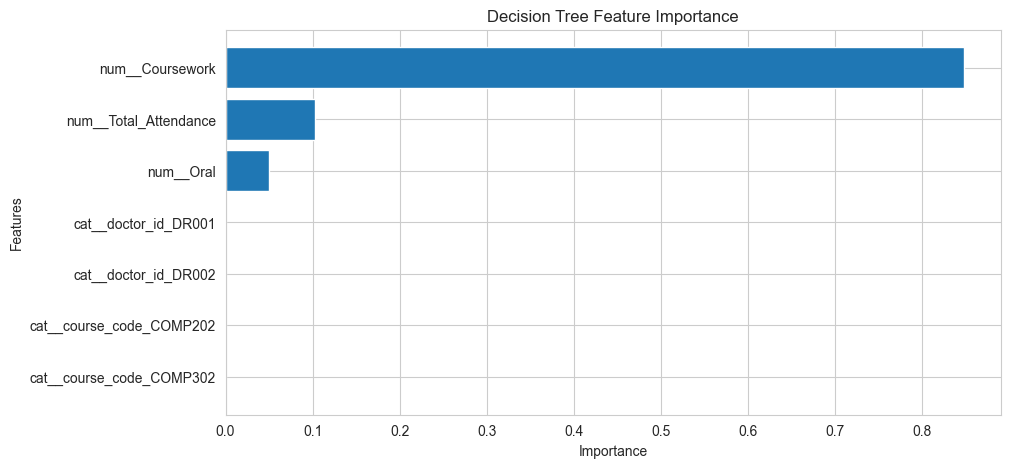

In [24]:
import pandas as pd

# Get the trained preprocessing pipeline
preprocessor_fitted = best_model.named_steps["preprocessor"]

# Get feature names after preprocessing
feature_names = preprocessor_fitted.get_feature_names_out()

# Get feature importance from Decision Tree
importances = best_model.named_steps["classifier"].feature_importances_

# Create DataFrame
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

# Sort from highest to lowest
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df)

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Decision Tree Feature Importance")
plt.gca().invert_yaxis()

plt.show()

In [25]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import make_scorer, f1_score

high_risk_f1 = make_scorer(
    f1_score,
    pos_label="High Risk"
)

perm_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring=high_risk_f1,
    n_repeats=20,
    random_state=42
)

permutation_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm_result.importances_mean,
    "Std": perm_result.importances_std
})

permutation_df = permutation_df.sort_values(
    by="Importance",
    ascending=False
)

print(permutation_df.round(4))

            Feature  Importance     Std
0        Coursework      0.3671  0.0313
2  Total_Attendance      0.0926  0.0182
1              Oral      0.0796  0.0284
3         doctor_id      0.0000  0.0000
4       course_code      0.0000  0.0000


In [28]:
new_student = pd.DataFrame([{
    "Coursework": 25,
    "Oral": 8,
    "Total_Attendance": 6,
    "doctor_id": "DR002",
    "course_code": "COMP202"
}])

y_predict = best_model.predict(new_student)

print("Predicted Risk:", y_predict[0])

Predicted Risk: Low Risk
